## Agentic AI for Enrichment: Preliminary Investigation

This notebook focus on the preliminary investigation on the use of Agentic AI in the context of metadata enrichment.

Author: Boon Heng Chew <<s2831745@sms.ed.ac.uk>>

> Link to **Research Question:** Does agentic enrichment of extracted structural metadata improve cross language repository similarity ranking accuracy compared to unenriched metadata?

This notebook implements the **core agentic enrichment pipeline** using:
- `LangGraph` - ReAct-style agent graph (Thought -> Action -> Observation loop)
- `OpenAI GPT-5` - LLM backbone
- `inspect4j` output - real Java repository metadata (java-jwt) as input

#### Experiment Agentic Workflow
- Load inspect4j JSON output from the software project / git repository `java-jwt`
- Flatten into a list of method records
- Run a LangGraph ReAct agent that:
  1. Detects gaps (methods with missing documentation)
  2. Enriches each gap with a generated docstring via `enrich_docstring` tool
  3. Tags each field with provenance: `tool | agent_backfill | missing`
  4. Emits `finish` when gaps are exhausted (max-step cap = 20)
- Compare before/after metadata quality

In [1]:
from platform import python_version

# show environment
print(f"Python environment: {python_version()}")

Python environment: 3.12.4


#### 1. Setup & Configuration

In [2]:
import json
import os
import random
from pathlib import Path
from typing import Annotated, Any, TypedDict

from dotenv import load_dotenv

# Leverage on dotenv to hide and load API Key to ELM OpenAI
load_dotenv()

api_key = os.getenv('OPENAI_API_KEY')
if not api_key:
    raise EnvironmentError(
        'OPENAI_API_KEY not found. Create a .env file in this directory with:\n'
        'OPENAI_API_KEY=sk-...'
    )
print('[OK] OPENAI_API_KEY loaded')

[OK] OPENAI_API_KEY loaded


In [3]:

# LLM related configuration
LLM_MODEL = "gpt-5.4"
REASONING_EFFORT = "low" # default is none

# Workflow configuration
INSPECT4J_OUTPUT = Path('data/sample_inspect4j_directory_info.json')
""" a sample output from inspect4j """

MAX_ENRICHMENT_STEPS = 20
""" Control the max step to take to avoid infinite loop when agent can't reach exit condition"""

MAX_RETRY_ENRICHMENT = 2
""" Max Reflexion-style retries per method when validation fails (P68 Reflexion) """

SAMPLE_SIZE_EACH = 5
""" The number of methods to enrich on. """

RANDOM_SEED = 42

print(f'Input:      {INSPECT4J_OUTPUT}')
print(f'Model:      {LLM_MODEL}')
VALIDATION_CONFIDENCE_THRESHOLD = 0.7
""" Confidence threshold for validate_enrichment. 0.7 for GPT (high quality), 0.6 for local models (prevent infinite loop). """

print(f'Max steps:  {MAX_ENRICHMENT_STEPS}')
print(f'Max retries:{MAX_RETRY_ENRICHMENT}')
print(f'Confidence: {VALIDATION_CONFIDENCE_THRESHOLD}')

Input:      data/sample_inspect4j_directory_info.json
Model:      gpt-5.4
Max steps:  20
Max retries:2
Confidence: 0.7


#### 2. Load & Flatten inspect4j Output

In [4]:
def load_inspect4j(path: Path) -> list[dict[str, Any]]:
    """Flatten nested inspect4j directory_info.json into a list of method records."""
    with path.open(encoding='utf-8') as f:
        data = json.load(f)
    methods = []
    for _pkg_key, files in data.items():
        for file_info in files:
            file_path = file_info.get('file', {}).get('path', '')
            pkg_name = file_info.get('package', {}).get('name', '')
            deps = file_info.get('dependencies', [])
            for cls_name, cls_data in file_info.get('classes', {}).items():
                for method_name, method_data in cls_data.get('methods', {}).items():
                    doc = method_data.get('doc', {}) or {}
                    description = doc.get('description', '').strip()
                    methods.append({
                        'id': f'{pkg_name}.{cls_name}.{method_name}',
                        'file': file_path,
                        'package': pkg_name,
                        'class': cls_name,
                        'method': method_name,
                        'modifiers': method_data.get('modifiers', []),
                        'parameters': method_data.get('parameters', []),
                        'return_type': method_data.get('return_type'),
                        'annotations': method_data.get('annotations', []),
                        'calls': method_data.get('calls', []),
                        'doc': {'description': description, 'tags': doc.get('comment_tags', {})},
                        'class_deps': [d.get('from_module') for d in deps],
                        'provenance': {'doc': 'tool' if description else 'missing'},
                    })
    return methods


all_methods = load_inspect4j(INSPECT4J_OUTPUT)
methods_with_doc = [m for m in all_methods if m['provenance']['doc'] == 'tool']
methods_missing_doc = [m for m in all_methods if m['provenance']['doc'] == 'missing']

print(f'Total methods:         {len(all_methods)}')
print(f'With documentation:    {len(methods_with_doc)} ({len(methods_with_doc)/len(all_methods)*100:.1f}%)')
print(f'Missing documentation: {len(methods_missing_doc)} ({len(methods_missing_doc)/len(all_methods)*100:.1f}%)')

Total methods:         924
With documentation:    55 (6.0%)
Missing documentation: 869 (94.0%)


In [5]:
random.seed(RANDOM_SEED)
sample_with_doc = random.sample(methods_with_doc, min(SAMPLE_SIZE_EACH, len(methods_with_doc)))
sample_missing_doc = random.sample(methods_missing_doc, min(SAMPLE_SIZE_EACH, len(methods_missing_doc)))
experiment_sample = sample_with_doc + sample_missing_doc

print(f'Experiment sample: {len(experiment_sample)} methods')
print(f'  {len(sample_with_doc)} with existing docs (control group)')
print(f'  {len(sample_missing_doc)} missing docs (treatment -- to enrich)')
print()
m = sample_with_doc[0]
print('Example (control):')
print(f'  {m["id"]}')
print(f'  Doc Description: {m["doc"]["description"][:120]}')
print()
m = sample_missing_doc[0]
params_str = ", ".join(f'{p["type"]} {p["name"]}' for p in m["parameters"])
print('Example (treatment):')
print(f'  {m["id"]}')
print(f'  Signature: {m["method"]}({params_str}) -> {m["return_type"]}')
print(f'  Doc Description: <none>')

Experiment sample: 10 methods
  5 with existing docs (control group)
  5 missing docs (treatment -- to enrich)

Example (control):
  com.auth0.jwt.algorithms.CryptoHelper.verifySignatureFor(String,PublicKey,String,String,byte[])
  Doc Description: Verify signature for JWT header and payload.

Example (treatment):
  com.auth0.jwt.JWTDecoderTest.shouldGetIssuedAt
  Signature: shouldGetIssuedAt() -> None
  Doc Description: <none>


## 3. LangGraph ReAct Enrichment Agent

The agent follows the **ReAct pattern** (Yao et al., 2022) with a three-layer quality mechanism:

```
START -> agent (Thought) -> tools (Action+Observation) -> agent -> ... -> END

  Step 1: detect_gaps         -- analyse all methods, produce structured gap report

  Step 2: enrich_docstring    -- generate docstring with:
        * component-type-specific prompt (constructor / test / static / instance)  [DocAgent]
        * dependency context: already-enriched docstrings of called methods        [DocAgent + Structured metadata as context]
        * optional feedback from failed validation for Reflexion retry             [Reflexion]

  Step 3: validate_enrichment -- three-dimensional check:
        Dim 1 Helpfulness:   LLM-as-judge coherence + hallucination check          [CRAG]
        Dim 2 Truthfulness:  entity cross-reference against _method_registry       [DocAgent + Structured metadata as context]
        Dim 3 Reflexion gate: retry decision with verbal feedback                  [Reflexion]
        +-- PASS (confidence >= 0.7, entities verified) -> provenance: agent_enriched
        +-- FAIL + retries remaining -> retry_recommended=True
        |     -> enrich_docstring(method_id, feedback=retry_feedback)  [Reflexion loop]
        \-- FAIL + retries exhausted -> provenance: agent_backfill_unvalidated

  Step 4: finish              -- summarise what was done
```

### Tools registered

| Tool | Purpose | Theory |
|------|---------|--------|
| `detect_gaps` | Structured gap analysis -- missing doc, weak doc, javalang parse failures | ReAct |
| `enrich_docstring` | Type-specific prompt + dependency context + Reflexion feedback support | DocAgent, Reflexion |
| `validate_enrichment` | Helpfulness (LLM-judge) + Truthfulness (entity check) + Reflexion gate | CRAG, Refexion, DocAgent |
| `finish` | Signal enrichment complete | -- |

In [6]:
import re

from langchain_core.messages import AnyMessage, HumanMessage
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode


class EnrichmentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
    methods_to_enrich: list[dict]
    enriched: list[dict]
    step_count: int
    finished: bool


# --- Registries ---
# Ground-truth method dicts: tools look up by ID, never trust LLM-reconstructed dicts
_method_registry: dict[str, dict] = {}
# Enriched registry: written by enrich_docstring, updated by validate_enrichment
_enriched_registry: dict[str, dict] = {}
# Retry counter: tracks Reflexion retry attempts per method
_retry_registry: dict[str, int] = {}

# --- Constants ---
_JAVALANG_UNPARSEABLE_ANNOTATIONS = {
    'RestController', 'Controller', 'Service', 'Repository',
    'Component', 'SpringBootApplication', 'Configuration',
    'Data', 'Builder', 'Getter', 'Setter',
}
_WEAK_DOC_MAX_CHARS = 30
_VALIDATION_CONFIDENCE_THRESHOLD = VALIDATION_CONFIDENCE_THRESHOLD

# Java standard types excluded from truthfulness check (too common to flag)
_JAVA_BUILTINS = {
    'String', 'Integer', 'Double', 'Float', 'Long', 'Boolean', 'Byte', 'Short',
    'Object', 'Class', 'Void', 'Number', 'Math', 'System',
    'List', 'Map', 'Set', 'Collection', 'Iterator', 'Optional',
    'Exception', 'RuntimeException', 'IllegalArgumentException',
    'IllegalStateException', 'NullPointerException', 'UnsupportedOperationException',
    # JWT project-level types that appear ubiquitously (too broad to flag)
    'JWT', 'Claim', 'Algorithm', 'DecodedJWT', 'Payload', 'Header',
    'JsonNode', 'ObjectMapper', 'Date', 'Instant',
}


# --- Helpers ---

def _extract_text(content: str | list) -> str:
    """Extract plain text from LLM response (Chat Completions str or Responses API list)."""
    if isinstance(content, str):
        return content.strip()
    return ''.join(
        block.get('text', '') if isinstance(block, dict) else str(block)
        for block in content
    ).strip()


def _classify_gaps(method: dict) -> list[str]:
    """Classify what metadata gaps exist in a single method record."""
    gaps = []
    description = method.get('doc', {}).get('description', '').strip()
    if not description:
        gaps.append('missing_docstring')
    elif len(description) < _WEAK_DOC_MAX_CHARS:
        gaps.append('weak_docstring')
    return_type = method.get('return_type')
    is_constructor = method['method'] == method['class']
    if not is_constructor and return_type is None:
        gaps.append('missing_return_type')
    annotation_names = {a.get('name', '') for a in method.get('annotations', [])}
    unparseable = annotation_names & _JAVALANG_UNPARSEABLE_ANNOTATIONS
    if unparseable:
        gaps.append(f'unparsed_construct:{",".join(sorted(unparseable))}')
    return gaps


def _detect_method_type(method: dict) -> str:
    """Classify method type for component-type-specific prompting (DocAgent Writer templates)."""
    method_name = method['method']
    class_name = method['class']
    modifiers = method.get('modifiers', [])
    annotation_names = {a.get('name', '') for a in method.get('annotations', [])}
    _test_annotations = {'Test', 'ParameterizedTest', 'BeforeEach', 'AfterEach', 'BeforeAll', 'AfterAll'}
    if method_name == class_name:
        return 'constructor'
    if annotation_names & _test_annotations or method_name.startswith(('test', 'should')):
        return 'test'
    if 'static' in modifiers:
        return 'static'
    return 'instance'


def _build_dependency_context(method: dict) -> str:
    """Build context from already-enriched docstrings of called methods.

    Implements DocAgent's 'Dependencies First' principle: when documenting method A
    that calls method B, include B's already-enriched docstring as grounding context.
    This reduces hallucination and improves specificity.
    """
    lines = []
    for call_name in method.get('calls', [])[:5]:
        call_short = call_name.split('.')[-1]
        for mid, enriched in _enriched_registry.items():
            mid_method = mid.split('.')[-1].split('(')[0]
            if mid_method == call_short:
                doc = enriched.get('doc', {}).get('description', '').strip()
                if doc:
                    lines.append(f'  - {call_short}: {doc[:100]}')
                break
    return '\n'.join(lines)


def _extract_code_entities(text: str) -> set[str]:
    """Extract code entity references from a docstring for truthfulness checking."""
    entities: set[str] = set()
    # Javadoc cross-references: {@link Foo}, {@code bar}
    entities.update(re.findall(r'\{@(?:link|code)\s+(\w+)', text))
    # UpperCamelCase class names
    entities.update(re.findall(r'\b([A-Z][a-z]+(?:[A-Z][a-z]*)+)\b', text))
    # Backtick code references: `foo`
    entities.update(re.findall(r'`(\w+)`', text))
    return entities


def _check_truthfulness(description: str) -> list[str]:
    """Verify code entities in the docstring exist in the method registry.

    DocAgent's truthfulness dimension: cross-reference mentioned entities against
    the AST-derived registry as ground truth to detect hallucinated references.
    """
    known: set[str] = set()
    for mid in _method_registry:
        known.update(mid.split('.'))
    known |= _JAVA_BUILTINS
    mentioned = _extract_code_entities(description)
    issues = [
        f'unverified entity: {e}'
        for e in sorted(mentioned)
        if len(e) >= 5 and e not in known
    ]
    return issues[:3]


def _build_enrich_prompt(
    method: dict,
    method_type: str,
    dependency_context: str,
    feedback: str,
) -> str:
    """Build a component-type-specific enrichment prompt (DocAgent Writer templates)."""
    params_str = ', '.join(f"{p['type']} {p['name']}" for p in method.get('parameters', []))
    return_type = method.get('return_type') or 'void'
    annotations = [a.get('name') for a in method.get('annotations', [])]
    modifiers = ' '.join(method.get('modifiers', []))
    _type_guidance = {
        'constructor': (
            'This is a CONSTRUCTOR. Describe: what state it initialises, '
            'what each parameter represents, and any validation or exception it may throw.'
        ),
        'test': (
            'This is a TEST METHOD. Describe: what behaviour or condition it verifies, '
            'what the expected outcome is, and what scenario is implied by the name.'
        ),
        'static': (
            'This is a STATIC UTILITY or FACTORY METHOD. Describe: what it computes or '
            'creates, input constraints, and what the return value represents.'
        ),
        'instance': (
            'This is an INSTANCE METHOD. Describe: the operation performed on object state, '
            'what each parameter controls, and what the return value represents.'
        ),
    }
    prompt = (
        'You are a Java documentation expert. Generate a concise Javadoc-style description '
        '(2-3 sentences) for the following Java method.\n\n'
        f'{_type_guidance[method_type]}\n\n'
        f"Class: {method['class']} (package: {method['package']})\n"
        f"Method signature: {modifiers} {return_type} {method['method']}({params_str})\n"
        f"Annotations: {annotations if annotations else 'none'}\n"
    )
    if dependency_context:
        prompt += (
            '\nDocumentation of called methods - use for context, do not copy verbatim:\n'
            f'{dependency_context}\n'
        )
    if feedback:
        prompt += (
            f'\nPrevious attempt was rejected. Issues identified:\n  {feedback}\n'
            'Please address these issues specifically in your revised description.\n'
        )
    prompt += '\nWrite ONLY the description text (no @param/@return tags). Be concise and accurate.'
    return prompt


# --- Tools ---

@tool
def detect_gaps(method_ids: list[str]) -> str:
    """Analyse a set of methods and produce a structured gap report.

    Diagnoses each method for:
    - missing_docstring: no documentation at all
    - weak_docstring: description exists but too short (<30 chars)
    - missing_return_type: null return type (e.g. likely a javalang parse failure on Java 9+ generics)
    - unparsed_construct:<name>: Spring/Lombok annotation javalang cannot resolve

    Args:
        method_ids: List of method IDs to analyse (format: 'package.Class.method').
    """
    gap_report: dict[str, list[str]] = {}
    no_gaps = []
    already_enriched = []
    for mid in method_ids:
        method = _method_registry.get(mid)
        if method is None:
            gap_report[mid] = ['not_found_in_registry']
            continue
        # Check enriched registry first -- reflects current pipeline state
        _ep = _enriched_registry.get(mid, {}).get('provenance', {}).get('doc', '')
        if _ep in ('agent_enriched', 'agent_backfill_unvalidated'):
            already_enriched.append(mid)
            continue
        gaps = _classify_gaps(method)
        if gaps:
            gap_report[mid] = gaps
        else:
            no_gaps.append(mid)
    if not gap_report:
        if already_enriched:
            return (
                f'All gaps resolved. {len(already_enriched)} method(s) enriched and finalised, '
                f'{len(no_gaps)} had no gaps originally. Call finish now.'
            )
        return 'No gaps detected. All methods have complete metadata.'
    lines = [f'Gap analysis for {len(method_ids)} methods:\n']
    if already_enriched:
        lines.append(f'  [done] {len(already_enriched)} already enriched/finalised -- do NOT re-process.')
    by_type: dict[str, list[str]] = {}
    for mid, gaps in gap_report.items():
        for g in gaps:
            by_type.setdefault(g, []).append(mid)
    for gap_type, affected in sorted(by_type.items()):
        lines.append(f'  [{gap_type}] ({len(affected)} methods):')
        for mid in affected[:8]:
            lines.append(f'    - {mid}')
        if len(affected) > 8:
            lines.append(f'    ... and {len(affected) - 8} more')
    lines.append(f'\n  No gaps: {len(no_gaps)} methods with sufficient existing metadata.')
    lines.append(
        '\nNext steps:'
        '\n  1. Call enrich_docstring for each method with missing_docstring or weak_docstring.'
        '\n  2. After each enrichment, call validate_enrichment to check quality.'
        '\n  3. If validate_enrichment returns retry_recommended=true, call enrich_docstring'
        '\n     again with the retry_feedback value as the feedback argument (Reflexion retry).'
        '\n  4. Methods with missing_return_type or unparsed_construct are javalang limitations'
        '\n     -- record them but do not attempt docstring enrichment.'
        '\n  5. Call finish once all gaps are resolved.'
    )
    return '\n'.join(lines)


@tool
def enrich_docstring(method_id: str, feedback: str = '') -> dict:
    """Generate an English Javadoc description for a Java method.

    Uses component-type-specific prompting (constructor / test / static / instance) and
    includes already-enriched docstrings of called methods as dependency context, following
    DocAgent's 'Dependencies First' principle to reduce hallucination.

    When a previous validate_enrichment failed, pass its retry_feedback here to trigger
    a Reflexion-style retry with verbal reinforcement.

    Args:
        method_id: The method ID in format 'package.Class.method'.
        feedback: Verbal feedback from a failed validation (leave empty on first attempt).
    """
    method = _method_registry.get(method_id)
    if method is None:
        return {'error': f'method_id "{method_id}" not found in registry'}
    # Guard: do not re-enrich a method already at final provenance
    _cur = _enriched_registry.get(method_id, {})
    _cur_prov = _cur.get('provenance', {}).get('doc', '')
    if _cur_prov in ('agent_enriched', 'agent_backfill_unvalidated'):
        return {
            'info': f'SKIP: "{method_id}" already finalised ({_cur_prov}). Move to the next method or call finish.',
            'provenance': _cur_prov,
        }
    method_type = _detect_method_type(method)
    dependency_context = _build_dependency_context(method)
    prompt = _build_enrich_prompt(method, method_type, dependency_context, feedback)
    llm = ChatOpenAI(model=LLM_MODEL, reasoning_effort=REASONING_EFFORT, use_responses_api=True, temperature=0)
    response = llm.invoke(prompt)
    generated_description = _extract_text(response.content)
    enriched = method.copy()
    enriched['doc'] = {'description': generated_description, 'tags': method.get('doc', {}).get('tags', {})}
    enriched['provenance'] = {**method.get('provenance', {}), 'doc': 'agent_backfill'}
    _enriched_registry[method_id] = enriched
    return enriched


@tool
def validate_enrichment(method_id: str) -> dict:
    """Validate the quality of a generated docstring using a three-dimensional check.

    Dim 1 Helpfulness:   LLM-as-judge coherence + hallucination check (CRAG).
    Dim 2 Truthfulness:  code entities in the docstring are cross-referenced against
                         _method_registry to detect hallucinated references (DocAgent + Reflexion).
    Dim 3 Reflexion gate: if validation fails and retries remain, returns
                          retry_recommended=True with retry_feedback (Reflexion).

    Provenance outcomes:
      agent_enriched           -- passed all dimensions
      agent_backfill           -- failed but retry available; call enrich_docstring(feedback=...)
      agent_backfill_unvalidated -- failed, retries exhausted

    Args:
        method_id: The method ID to validate (must have been enriched first).
    """
    enriched = _enriched_registry.get(method_id)
    if enriched is None:
        return {'error': f'No enriched record for "{method_id}". Call enrich_docstring first.'}
    # Guard: do not re-validate a method already at final provenance
    _vp = enriched.get('provenance', {}).get('doc', '')
    if _vp in ('agent_enriched', 'agent_backfill_unvalidated'):
        return {
            'info': f'SKIP: "{method_id}" already finalised ({_vp}). Move to the next method or call finish.',
            'method_id': method_id,
            'provenance': _vp,
        }
    method = _method_registry[method_id]
    description = enriched['doc']['description']
    params_str = ', '.join(f"{p['type']} {p['name']}" for p in method.get('parameters', []))
    return_type = method.get('return_type') or 'void'
    modifiers = ' '.join(method.get('modifiers', []))
    calls = method.get('calls', [])[:5]

    # Dim 1: Helpfulness -- LLM-as-judge
    validation_prompt = (
        'You are a code documentation quality reviewer. '
        'Assess the following generated Javadoc description against the method signature.\n\n'
        f"Method signature: {modifiers} {return_type} {method['method']}({params_str})\n"
        f"Class: {method['class']} (package: {method['package']})\n"
        f"Method calls: {calls if calls else 'none'}\n\n"
        f'Generated description:\n"{description}"\n\n'
        'Evaluate on three criteria:\n'
        '1. Accuracy: Does the description correctly describe what the method does?\n'
        '2. Hallucination: Does it mention parameters, types, or behaviours NOT present in the signature?\n'
        '3. Quality: Is it specific and useful, not just a restatement of the method name?\n\n'
        'Respond ONLY with valid JSON in this exact format (no markdown, no explanation):\n'
        '{"valid": true|false, "confidence": 0.0-1.0, "issues": ["issue1"]}'
    )
    llm = ChatOpenAI(model=LLM_MODEL, reasoning_effort=REASONING_EFFORT, use_responses_api=True, temperature=0)
    response = llm.invoke(validation_prompt)
    raw = _extract_text(response.content)
    try:
        clean = raw.strip().removeprefix('```json').removeprefix('```').removesuffix('```').strip()
        result = json.loads(clean)
        confidence = float(result.get('confidence', 0.0))
        llm_valid = result.get('valid', False)
        llm_issues = result.get('issues', [])
    except (json.JSONDecodeError, ValueError):
        llm_valid = False
        confidence = 0.0
        llm_issues = [f'validator_parse_error: {raw[:100]}']

    # Dim 2: Truthfulness (entity cross-reference)
    truth_issues = _check_truthfulness(description)
    if truth_issues:
        confidence = max(0.0, confidence - 0.1 * len(truth_issues))
    all_issues = llm_issues + truth_issues
    valid = llm_valid and confidence >= _VALIDATION_CONFIDENCE_THRESHOLD

    # Dim 3: Reflexion retry gate
    retries_used = _retry_registry.get(method_id, 0)
    retry_available = not valid and retries_used < MAX_RETRY_ENRICHMENT
    if valid:
        final_provenance = 'agent_enriched'
    elif retry_available:
        final_provenance = 'agent_backfill'  # remains mutable until retries exhausted or pass
        _retry_registry[method_id] = retries_used + 1
    else:
        final_provenance = 'agent_backfill_unvalidated'

    enriched['provenance']['doc'] = final_provenance
    _enriched_registry[method_id] = enriched

    out: dict = {
        'method_id': method_id,
        'valid': valid,
        'confidence': round(confidence, 3),
        'issues': all_issues,
        'truthfulness_issues': truth_issues,
        'provenance': final_provenance,
        'description_preview': description[:120],
    }
    if retry_available:
        feedback_str = '; '.join(all_issues) if all_issues else 'low confidence -- improve specificity'
        out['retry_recommended'] = True
        out['retry_feedback'] = feedback_str
        out['retries_remaining'] = MAX_RETRY_ENRICHMENT - _retry_registry[method_id]
        out['action'] = (
            f'Call enrich_docstring(method_id="{method_id}", feedback="{feedback_str}") '
            f'to retry with Reflexion verbal feedback.'
        )
    return out


@tool
def finish(summary: str) -> str:
    """Signal that enrichment is complete and provide a summary."""
    return f'ENRICHMENT COMPLETE: {summary}'


tools = [detect_gaps, enrich_docstring, validate_enrichment, finish]
print(f'[OK] {len(tools)} tools registered: {[t.name for t in tools]}')
print('  enrich_docstring:    component-type prompts + dependency context')
print('  validate_enrichment: helpfulness + truthfulness + Reflexion gate')

[OK] 4 tools registered: ['detect_gaps', 'enrich_docstring', 'validate_enrichment', 'finish']
  enrich_docstring:    component-type prompts + dependency context
  validate_enrichment: helpfulness + truthfulness + Reflexion gate


In [7]:
llm = ChatOpenAI(model=LLM_MODEL, reasoning_effort=REASONING_EFFORT, use_responses_api=True, temperature=0)
llm_with_tools = llm.bind_tools(tools)


def agent_node(state: EnrichmentState) -> dict:
    """Agent reasoning node -- LLM decides the next action."""
    response = llm_with_tools.invoke(state['messages'])
    return {'messages': [response]}


def should_continue(state: EnrichmentState) -> str:
    """Routing: continue ReAct loop or terminate.

    Three exit conditions (checked in priority order):
      1. Hard step cap  - MAX_ENRICHMENT_STEPS reached (safety, model-agnostic)
      2. Semantic exit  - all treatment methods have a final provenance in the enriched
                          registry (model-agnostic; does not require the model to call finish)
      3. Model exit     - model called finish, or emitted no tool calls
    """
    # 1. Hard safety cap -- always respected regardless of model behaviour
    if state['step_count'] >= MAX_ENRICHMENT_STEPS:
        print(f'  [SAFETY] Max steps ({MAX_ENRICHMENT_STEPS}) reached -- terminating.')
        return END

    # 2. Semantic completion check -- exit as soon as all gaps are resolved
    treatment_ids = {
        m['id'] for m in state['methods_to_enrich']
        if m['provenance']['doc'] == 'missing'
    }
    if treatment_ids:
        _final = ('agent_enriched', 'agent_backfill_unvalidated')
        all_done = all(
            _enriched_registry.get(mid, {}).get('provenance', {}).get('doc') in _final
            for mid in treatment_ids
        )
        if all_done:
            print(f'  [AUTO-EXIT] All {len(treatment_ids)} treatment methods validated -- terminating.')
            return END

    # 3. Model-driven exit -- finish tool call or no tool calls
    last_message = state['messages'][-1]
    tool_calls = getattr(last_message, 'tool_calls', [])
    if not tool_calls:
        return END
    for tc in tool_calls:
        if tc['name'] == 'finish':
            return END
    return 'tools'


def increment_step(state: EnrichmentState) -> dict:
    """Increment the step counter after each tool execution."""
    new_count = state['step_count'] + 1
    print(f'  Step {new_count}: tool executed')
    return {'step_count': new_count}


tool_node = ToolNode(tools)
builder = StateGraph(EnrichmentState)
builder.add_node('agent', agent_node)
builder.add_node('tools', tool_node)
builder.add_node('step_counter', increment_step)
builder.add_edge(START, 'agent')
builder.add_conditional_edges('agent', should_continue, {'tools': 'tools', END: END})
builder.add_edge('tools', 'step_counter')
builder.add_edge('step_counter', 'agent')
graph = builder.compile()

print('[OK] LangGraph agent compiled')
print('  Graph: START -> agent -> [tools -> step_counter -> agent]* -> END')
print('  Exit:  step_cap | all_validated | finish | no_tool_calls')

[OK] LangGraph agent compiled
  Graph: START -> agent -> [tools -> step_counter -> agent]* -> END
  Exit:  step_cap | all_validated | finish | no_tool_calls


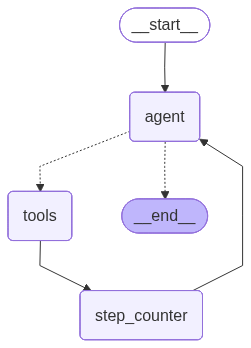

In [8]:
try:
    from IPython.display import Image, display
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f'Graph visualisation unavailable: {e}')

## 4. Run the Enrichment Agent

In [9]:
def build_prompt(methods: list[dict]) -> str:
    """Build the initial agent prompt.

    Passes ALL methods (with and without docs) so the agent must call detect_gaps
    first to discover which ones need enrichment (proper ReAct analysis step).
    """
    lines = []
    for i, m in enumerate(methods):
        params = ', '.join(f"{p['type']} {p['name']}" for p in m.get('parameters', []))
        lines.append(f"  {i+1}. {m['id']}  ({m['class']}.{m['method']}({params}) -> {m['return_type'] or 'void'})")
    method_list = '\n'.join(lines)

    return (
        f'You are an agentic metadata enrichment system for the Java repository "java-jwt".\n\n'
        f'You have been given {len(methods)} method IDs from this repository. '
        f'Some methods already have documentation; others do not.\n\n'
        f'Your task:\n'
        f'  1. Call `detect_gaps` with ALL method IDs below to identify which methods need documentation.\n'
        f'  2. For each method with missing_docstring or weak_docstring, call `enrich_docstring`.\n'
        f'  3. After each enrich_docstring call, call `validate_enrichment` to check quality.\n'
        f'  4. If validate_enrichment returns retry_recommended=true, call `enrich_docstring` again\n'
        f'     with the retry_feedback value as the feedback argument (Reflexion retry, max {MAX_RETRY_ENRICHMENT} retries).\n'
        f'  5. Call `finish` with a summary once all gaps are resolved.\n\n'
        f'Method IDs to analyse:\n{method_list}\n\n'
        f'Start by calling detect_gaps to understand the current state of the metadata.'
    )


# Pass the FULL experiment sample (both control + treatment) -- agent must discover gaps itself
initial_prompt = build_prompt(experiment_sample)
print(initial_prompt)

You are an agentic metadata enrichment system for the Java repository "java-jwt".

You have been given 10 method IDs from this repository. Some methods already have documentation; others do not.

Your task:
  1. Call `detect_gaps` with ALL method IDs below to identify which methods need documentation.
  2. For each method with missing_docstring or weak_docstring, call `enrich_docstring`.
  3. After each enrich_docstring call, call `validate_enrichment` to check quality.
  4. If validate_enrichment returns retry_recommended=true, call `enrich_docstring` again
     with the retry_feedback value as the feedback argument (Reflexion retry, max 2 retries).
  5. Call `finish` with a summary once all gaps are resolved.

Method IDs to analyse:
  1. com.auth0.jwt.algorithms.CryptoHelper.verifySignatureFor(String,PublicKey,String,String,byte[])  (CryptoHelper.verifySignatureFor(String,PublicKey,String,String,byte[])(String algorithm, PublicKey publicKey, String header, String payload, byte[] sign

In [10]:
# Clear registries before running
_method_registry.clear()
_enriched_registry.clear()
_retry_registry.clear()
_method_registry.update({m['id']: m for m in all_methods})
print(f'[OK] Method registry:   {len(_method_registry)} methods')
print(f'[OK] Enriched registry: empty (will be populated by enrich_docstring)')
print(f'[OK] Retry registry:    empty')

initial_state: EnrichmentState = {
    'messages': [HumanMessage(content=initial_prompt)],
    'methods_to_enrich': experiment_sample,
    'enriched': [],
    'step_count': 0,
    'finished': False,
}

print(f'\nRunning agent on {len(experiment_sample)} methods...')
print(f'Expected trace: detect_gaps -> enrich+validate (xN) -> finish')
print('-' * 60)
final_state = graph.invoke(initial_state)
print('-' * 60)
print(f'Done. Steps used:       {final_state["step_count"]} / {MAX_ENRICHMENT_STEPS}')
print(f'Total messages:         {len(final_state["messages"])}')
print(f'Enriched registry:      {len(_enriched_registry)} records')
print(f'Retry registry:         {dict(_retry_registry) if _retry_registry else "no retries needed"}')

[OK] Method registry:   924 methods
[OK] Enriched registry: empty (will be populated by enrich_docstring)
[OK] Retry registry:    empty

Running agent on 10 methods...
Expected trace: detect_gaps -> enrich+validate (xN) -> finish
------------------------------------------------------------
  Step 1: tool executed
  Step 2: tool executed
  Step 3: tool executed
  Step 4: tool executed
  Step 5: tool executed
  [AUTO-EXIT] All 5 treatment methods validated -- terminating.
------------------------------------------------------------
Done. Steps used:       5 / 20
Total messages:         22
Enriched registry:      5 records
Retry registry:         {'com.auth0.jwt.JWTDecoderTest.shouldGetIssuedAt': 1, 'com.auth0.jwt.impl.PayloadImpl.getClaim': 1}


## 5. Extract & Inspect Results

In [11]:
def extract_enriched_from_trace(final_state: EnrichmentState) -> list[dict]:
    """Extract final enriched method dicts from the enriched registry.

    Uses _enriched_registry (updated by both enrich_docstring and validate_enrichment)
    so provenance reflects the final validated state, not the initial backfill state.
    """
    return list(_enriched_registry.values())


enriched_methods = extract_enriched_from_trace(final_state)
print(f'Extracted {len(enriched_methods)} enriched method records')
print()

# Show provenance breakdown from validation
prov_counts: dict[str, int] = {}
for m in enriched_methods:
    p = m['provenance']['doc']
    prov_counts[p] = prov_counts.get(p, 0) + 1

print('Provenance after validation:')
for prov, count in sorted(prov_counts.items()):
    icon = 'OK' if prov == 'agent_enriched' else 'NV' if 'unvalidated' in prov else '?'
    print(f'  {icon} {prov:30s} {count} methods')

Extracted 5 enriched method records

Provenance after validation:
  OK agent_enriched                 5 methods


In [12]:
print('=' * 70)
print('AGENT CONVERSATION TRACE')
print('=' * 70)

for i, msg in enumerate(final_state['messages']):
    msg_type = type(msg).__name__
    if msg_type == 'HumanMessage':
        print(f'\n[{i}] HumanMessage:')
        print(f'  {str(msg.content)[:200]}...')
    elif msg_type == 'AIMessage':
        tool_calls = getattr(msg, 'tool_calls', [])
        print(f'\n[{i}] AIMessage ({len(tool_calls)} tool calls):')
        for tc in tool_calls:
            args_preview = str(tc.get('args', {}))[:120]
            print(f'  -> {tc["name"]}({args_preview})')
    elif msg_type == 'ToolMessage':
        tool_name = getattr(msg, 'name', '?')
        content_preview = str(msg.content)[:250]
        print(f'\n[{i}] ToolMessage [{tool_name}]:')
        print(f'  {content_preview}')

AGENT CONVERSATION TRACE

[0] HumanMessage:
  You are an agentic metadata enrichment system for the Java repository "java-jwt".

You have been given 10 method IDs from this repository. Some methods already have documentation; others do not.

Your...

[1] AIMessage (1 tool calls):
  -> detect_gaps({'method_ids': ['com.auth0.jwt.algorithms.CryptoHelper.verifySignatureFor(String,PublicKey,String,String,byte[])', 'com.)

[2] ToolMessage [detect_gaps]:
  Gap analysis for 10 methods:

  [missing_docstring] (5 methods):
    - com.auth0.jwt.JWTDecoderTest.shouldGetIssuedAt
    - com.auth0.jwt.JWTCreatorTest.shouldFailWithIllegalArgumentExceptionForInvalidJsonForPayloadClaims
    - com.auth0.jwt.impl.Pay

[3] AIMessage (5 tool calls):
  -> enrich_docstring({'method_id': 'com.auth0.jwt.JWTDecoderTest.shouldGetIssuedAt', 'feedback': ''})
  -> enrich_docstring({'method_id': 'com.auth0.jwt.JWTCreatorTest.shouldFailWithIllegalArgumentExceptionForInvalidJsonForPayloadClaims', 'feed)
  -> enrich_docst

In [13]:
print('=' * 70)
print('BEFORE / AFTER ENRICHMENT')
print('=' * 70)

enriched_by_id = {m['id']: m for m in enriched_methods}

for original in sample_missing_doc:
    enriched = enriched_by_id.get(original['id'])
    params_str = ', '.join(f"{p['type']} {p['name']}" for p in original['parameters'])
    print(f"\n  Method: {original['id']}")
    print(f"  Sig:    {original['method']}({params_str}) -> {original['return_type']}")
    print(f"  BEFORE: <no documentation>  [provenance: {original['provenance']['doc']}]")
    if enriched:
        after_doc = enriched['doc'].get('description', '<none>')
        print(f"  AFTER:  {after_doc}")
        print(f"          [provenance: {enriched['provenance']['doc']}]")
    else:
        print('  AFTER:  <not enriched by agent>')
    print('-' * 60)

BEFORE / AFTER ENRICHMENT

  Method: com.auth0.jwt.JWTDecoderTest.shouldGetIssuedAt
  Sig:    shouldGetIssuedAt() -> None
  BEFORE: <no documentation>  [provenance: missing]
  AFTER:  Verifies that a decoded JWT exposes its issued-at claim through the corresponding accessor. The expected outcome is that calling {@code getIssuedAt()} returns the issued-at value rather than omitting it. The method name implies a scenario where a token containing an issued-at claim is decoded and that claim is then retrieved.
          [provenance: agent_enriched]
------------------------------------------------------------

  Method: com.auth0.jwt.JWTCreatorTest.shouldFailWithIllegalArgumentExceptionForInvalidJsonForPayloadClaims
  Sig:    shouldFailWithIllegalArgumentExceptionForInvalidJsonForPayloadClaims() -> None
  BEFORE: <no documentation>  [provenance: missing]
  AFTER:  Verifies that creating a JWT with payload claims containing invalid JSON is rejected. The expected outcome is that an {@link Ill

## 6. Save Output with Provenance

In [14]:
enriched_by_id = {m['id']: m for m in enriched_methods}
merged_sample = [
    enriched_by_id.get(m['id'], m) for m in experiment_sample
]

output_path = Path('output_enriched_sample.json')
with output_path.open('w', encoding='utf-8') as f:
    json.dump(merged_sample, f, indent=2, ensure_ascii=False)

print(f'OK: Saved {len(merged_sample)} method records -> {output_path}')
print()

prov_counts: dict[str, int] = {}
for m in merged_sample:
    p = m['provenance']['doc']
    prov_counts[p] = prov_counts.get(p, 0) + 1

print('Provenance breakdown:')
for prov, count in sorted(prov_counts.items()):
    print(f'  {prov:20s}  {count} methods')

OK: Saved 10 method records -> output_enriched_sample.json

Provenance breakdown:
  agent_enriched        5 methods
  tool                  5 methods


In [15]:
merged_sample

[{'id': 'com.auth0.jwt.algorithms.CryptoHelper.verifySignatureFor(String,PublicKey,String,String,byte[])',
  'file': 'D:\\FinalProject\\inspect4j\\Test\\test_repos\\java-jwt-master\\java-jwt-master\\lib\\src\\main\\java\\com\\auth0\\jwt\\algorithms\\CryptoHelper.java',
  'package': 'com.auth0.jwt.algorithms',
  'class': 'CryptoHelper',
  'method': 'verifySignatureFor(String,PublicKey,String,String,byte[])',
  'modifiers': [],
  'parameters': [{'name': 'algorithm', 'type': 'String'},
   {'name': 'publicKey', 'type': 'PublicKey'},
   {'name': 'header', 'type': 'String'},
   {'name': 'payload', 'type': 'String'},
   {'name': 'signatureBytes', 'type': 'byte[]'}],
  'return_type': 'boolean',
  'annotations': [],
  'calls': ['CryptoHelper.CryptoHelper.verifySignatureFor',
   'String.getBytes',
   'String.getBytes'],
  'doc': {'description': 'Verify signature for JWT header and payload.',
   'tags': {'param': ['algorithm      algorithm name.',
     'publicKey      algorithm public key.',
    

## 7. Observations & Next Steps

### What this experiment demonstrates

| Aspect | Result |
|--------|--------|
| **Gap detection** | Agent identifies methods without doc (java-jwt) |
| **Docstring generation** | GPT 5.4 produces contextually accurate descriptions using signatures, annotations, and call lists |
| **Provenance tagging** | `tool` (original) vs `agent_backfill` (enriched) enables ablation in RQ2 evaluation |
| **ReAct loop** | LangGraph Thought->Action->Observation cycle executes correctly |
| **Step cap** | MAX_ENRICHMENT_STEPS guard prevents runaway loops |
